# 02: What separates winning replies from losing ones?

Each pair holds two challenger threads replying to the **same** original post: one won a delta, one didn't.
Comparing them **within the pair** holds the topic, the OP, and the timing of the post fixed, so differences reflect
the replies themselves.

**Method**
- Length is the known confound (notebook 01: "longer wins" is right 67% of the time). Every feature is tested
  **after adjusting for the length difference**, using a paired (conditional) logistic regression on winner-minus-loser
  differences. Confidence intervals are clustered by original post, since several pairs share an OP.
- As a robustness check, each feature is also compared on a **length-matched subset**: pairs whose two threads are within
  20% of each other's word count.
- **Train split only.** The heldout split stays untouched so findings can be confirmed and models evaluated there.

Features are simple lexicon counts from `features.py`: rough proxies for ethos/pathos/logos, not validated measures.

In [1]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, NullLocator, PercentFormatter
from sklearn.feature_extraction.text import CountVectorizer

import cmv_data as cd
import features as ft
import viz
from viz import INK, INK2, NEUTRAL, SURFACE, AXIS, WIN, LOSE

viz.apply_style()
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

pairs_all, args_all = cd.load_pairs()
pairs = pairs_all[pairs_all.split == "train"].reset_index(drop=True)
args = args_all[args_all.split == "train"].reset_index(drop=True)
A = pd.concat([args, ft.extract_frame(args, pairs)], axis=1)   # ~15 s
print(f"{len(pairs)} train pairs, {len(A)} threads")

3456 train pairs, 6912 threads


In [2]:
# Submission timestamps from all/. The first run streams the 2.2 GB training file (~40 s) and caches a small table.
cache = cd.DATA_DIR.parent / "interim" / "submissions_train.pkl"
if cache.exists():
    subs = pd.read_pickle(cache)
else:
    rows = []
    for s in cd.iter_all_submissions("train"):
        comments = s["comments"]
        rows.append({
            "op_name": s["name"], "op_created": s["created_utc"], "n_comments": len(comments),
            "n_top_level": sum((c.get("parent_id") or "").startswith("t3_") for c in comments),
            "n_commenters": len({c.get("author") for c in comments} - {"[deleted]", "DeltaBot", s["author"], None}),
        })
    subs = pd.DataFrame(rows)
    cache.parent.mkdir(parents=True, exist_ok=True)
    subs.to_pickle(cache)

A["delay_hours"] = (A.created_utc - A.op_name.map(subs.set_index("op_name").op_created)) / 3600
A["joined_earlier"] = -np.log(A.delay_hours.clip(lower=1 / 60))   # higher = joined sooner after the OP posted

# Interaction features (research question 2) join the text features.
FEATURES = dict(ft.FEATURES) | {
    "joined_earlier": ("Interaction (Q2)", "minus log hours between the OP and the challenger's first reply"),
    "n_comments": ("Interaction (Q2)", "challenger comments in the thread (back-and-forth with the OP)"),
}
LABELS = dict(ft.LABELS) | {"joined_earlier": "Joined the discussion earlier", "n_comments": "More comments (back-and-forth)"}

W = A[A.is_winner == 1].set_index("pair_id")
L = A[A.is_winner == 0].set_index("pair_id").loc[W.index]
groups = pd.factorize(W.op_name)[0]   # cluster id = original post
print(f"timestamps found for {A.delay_hours.notna().mean():.0%} of threads")

timestamps found for 100% of threads


## 1. Two ways to take length out of the comparison

In [3]:
ratio = np.maximum(W.n_words, L.n_words) / np.minimum(W.n_words, L.n_words).clip(lower=1)
matched = (ratio <= 1.2).to_numpy()

def longer_wins(mask):
    w, l = W.n_words.to_numpy()[mask], L.n_words.to_numpy()[mask]
    return ((w > l) + 0.5 * (w == l)).mean()

pd.DataFrame({
    "pairs": [len(W), matched.sum()],
    "'longer thread wins' accuracy": [longer_wins(np.ones(len(W), bool)), longer_wins(matched)],
    "median words (winner)": [W.n_words.median(), W.n_words[matched].median()],
    "median words (loser)": [L.n_words.median(), L.n_words[matched].median()],
}, index=["all pairs (adjust for length in a model)", "length-matched subset (within 20%)"]).round(3)

,pairs,'longer thread wins' accuracy,median words (winner),median words (loser)
all pairs (adjust for length in a model),3456,0.669,260.0,175.0
length-matched subset (within 20%),557,0.512,212.0,211.0


Matching works (length drops to chance) but keeps only about 1 in 6 pairs, so its confidence intervals are wide. The
regression keeps all pairs and adjusts for length statistically, so it is the main analysis below. The matched subset
is a cross-check.

## 2. Which features favor the winner, once length is held fixed?
**Odds ratio per 1 SD:** if one thread scores 1 standard deviation higher on a feature than its opponent (and the two are
the same length), its odds of being the winner multiply by this number. 1 = no effect.

In [4]:
flip = np.random.default_rng(42).choice([-1, 1], len(W))   # random orientation: (A, B) instead of (winner, loser)
y = (flip > 0).astype(int)
dlen = flip * (np.log(W.n_words.clip(lower=1)) - np.log(L.n_words.clip(lower=1))).to_numpy()
fit_kw = dict(disp=0, cov_type="cluster", cov_kwds={"groups": groups})

boot_rng = np.random.default_rng(0)
def win_share(diff, g, n_boot=2000):
    """Share of non-tied pairs where diff > 0, with a cluster bootstrap 95% CI over g."""
    keep = diff != 0
    d, g = diff[keep], g[keep]
    if len(d) == 0:
        return np.nan, np.nan, np.nan
    wins = (d > 0).astype(float)
    codes, _ = pd.factorize(g)
    s, c = np.bincount(codes, weights=wins), np.bincount(codes)
    idx = boot_rng.integers(0, len(s), size=(n_boot, len(s)))
    lo, hi = np.percentile(s[idx].sum(1) / c[idx].sum(1), [2.5, 97.5])
    return wins.mean(), lo, hi

rows = []
for f, (family, desc) in FEATURES.items():
    diff = (W[f] - L[f]).to_numpy()
    ok = ~np.isnan(diff)
    d = flip * diff / A[f].std()
    raw = sm.Logit(y[ok], d[ok, None]).fit(**fit_kw | {"cov_kwds": {"groups": groups[ok]}})
    adj = sm.Logit(y[ok], np.column_stack([d[ok], dlen[ok]])).fit(**fit_kw | {"cov_kwds": {"groups": groups[ok]}})
    lo, hi = np.exp(adj.conf_int()[0])
    ws, ws_lo, ws_hi = win_share(diff[matched & ok], groups[matched & ok])
    rows.append({"feature": f, "label": LABELS[f], "family": family, "description": desc,
                 "OR (unadjusted)": np.exp(raw.params[0]), "OR (length-adjusted)": np.exp(adj.params[0]),
                 "CI low": lo, "CI high": hi, "p": adj.pvalues[0],
                 "matched win share": ws, "matched CI low": ws_lo, "matched CI high": ws_hi})
res = pd.DataFrame(rows)
bonferroni = 0.05 / len(res)
res["survives Bonferroni"] = res.p < bonferroni
res["verdict"] = np.select([res["CI low"] > 1, res["CI high"] < 1], ["favors winner", "favors loser"], "no clear difference")
print(f"{len(res)} features; Bonferroni threshold p < {bonferroni:.4f}")
res.groupby("verdict").size()

27 features; Bonferroni threshold p < 0.0019


verdict
favors loser            4
favors winner           5
no clear difference    18
dtype: int64

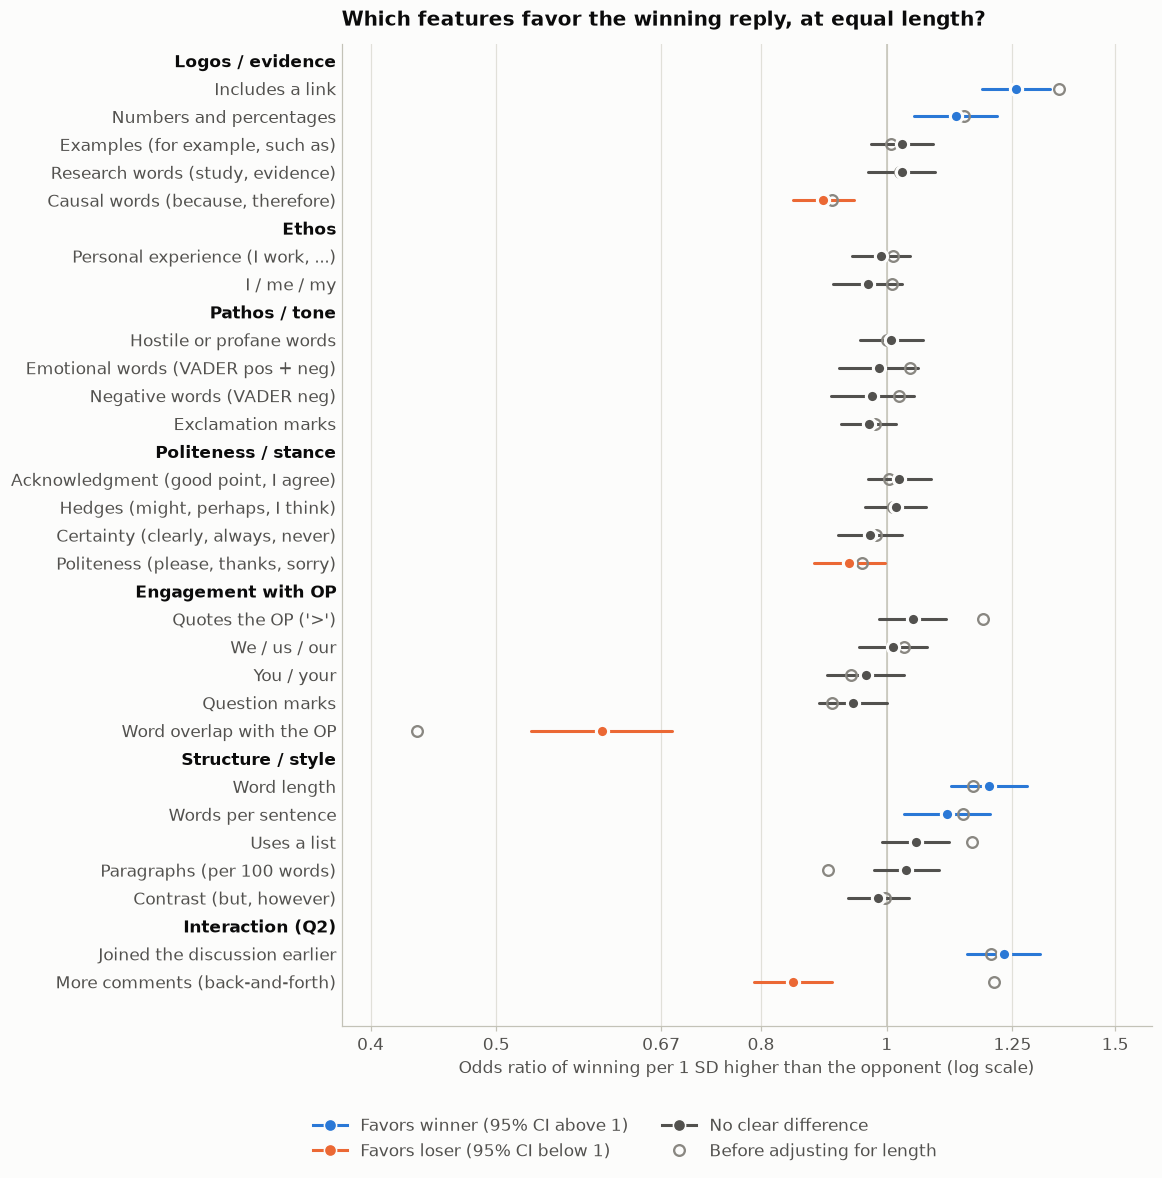

In [5]:
families = list(dict.fromkeys(fam for fam, _ in FEATURES.values()))
layout = []
for fam in families:
    layout.append(("header", fam, None))
    sub = res[res.family == fam].sort_values("OR (length-adjusted)", ascending=False)
    layout += [("feat", r["label"], r) for r in sub.to_dict("records")]

fig_h = 0.3 * len(layout) + 1.4
fig, ax = plt.subplots(figsize=(9.5, fig_h))
ys = np.arange(len(layout))[::-1]
color_for = {"favors winner": WIN, "favors loser": LOSE, "no clear difference": INK2}
for y_, (kind, _, r) in zip(ys, layout):
    if kind != "feat":
        continue
    c = color_for[r["verdict"]]
    ax.plot([r["CI low"], r["CI high"]], [y_, y_], color=c, lw=2, solid_capstyle="round")
    ax.plot(r["OR (unadjusted)"], y_, "o", ms=7, mfc="none", mec=NEUTRAL, mew=1.5, zorder=3)
    ax.plot(r["OR (length-adjusted)"], y_, "o", ms=8, color=c, mec=SURFACE, mew=2, zorder=4)
ax.axvline(1, color=AXIS, lw=1, zorder=1)
ax.set_xscale("log")
ticks = [0.4, 0.5, 0.67, 0.8, 1, 1.25, 1.5]
ax.xaxis.set_major_locator(FixedLocator(ticks))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xticklabels([f"{t:g}" for t in ticks])
ax.set_xlim(0.38, 1.6)
ax.set_yticks(ys, [lab for _, lab, _ in layout])
for tick, (kind, _, _) in zip(ax.get_yticklabels(), layout):
    if kind == "header":
        tick.set_fontweight("bold"); tick.set_color(INK)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio of winning per 1 SD higher than the opponent (log scale)")
ax.set_title("Which features favor the winning reply, at equal length?")
handles = [
    Line2D([], [], marker="o", ls="-", color=WIN, mec=SURFACE, ms=8, label="Favors winner (95% CI above 1)"),
    Line2D([], [], marker="o", ls="-", color=LOSE, mec=SURFACE, ms=8, label="Favors loser (95% CI below 1)"),
    Line2D([], [], marker="o", ls="-", color=INK2, mec=SURFACE, ms=8, label="No clear difference"),
    Line2D([], [], marker="o", ls="none", mfc="none", mec=NEUTRAL, mew=1.5, ms=7, label="Before adjusting for length"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.35, -0.9 / fig_h), ncol=2)
plt.show()

In [6]:
# Table view of the chart, sorted by adjusted odds ratio.
cols = ["label", "family", "OR (unadjusted)", "OR (length-adjusted)", "CI low", "CI high", "p", "survives Bonferroni",
        "matched win share", "matched CI low", "matched CI high"]
(res.sort_values("OR (length-adjusted)", ascending=False)[cols].style
    .format({c: "{:.2f}" for c in ["OR (unadjusted)", "OR (length-adjusted)", "CI low", "CI high"]}
            | {"p": "{:.4f}"} | {c: "{:.0%}" for c in ["matched win share", "matched CI low", "matched CI high"]})
    .hide(axis="index"))

label,family,OR (unadjusted),OR (length-adjusted),CI low,CI high,p,survives Bonferroni,matched win share,matched CI low,matched CI high
Includes a link,Logos / evidence,1.36,1.26,1.18,1.34,0.0000,True,66%,58%,74%
Joined the discussion earlier,Interaction (Q2),1.20,1.23,1.15,1.31,0.0000,True,57%,53%,61%
Word length,Structure / style,1.16,1.20,1.12,1.28,0.0000,True,51%,47%,56%
Numbers and percentages,Logos / evidence,1.15,1.13,1.05,1.22,0.0013,True,52%,47%,58%
Words per sentence,Structure / style,1.15,1.11,1.03,1.20,0.0066,False,53%,49%,58%
Uses a list,Structure / style,1.16,1.05,0.99,1.12,0.0882,False,51%,40%,63%
Quotes the OP ('>'),Engagement with OP,1.19,1.05,0.99,1.11,0.1315,False,53%,45%,60%
Paragraphs (per 100 words),Structure / style,0.90,1.04,0.98,1.10,0.2376,False,49%,46%,54%
"Examples (for example, such as)",Logos / evidence,1.01,1.03,0.97,1.09,0.3251,False,52%,45%,59%
"Research words (study, evidence)",Logos / evidence,1.02,1.03,0.97,1.09,0.3868,False,57%,50%,64%


**Reading the chart:** filled dots are length-adjusted, and hollow gray dots are the raw comparison. When a hollow dot sits
far from its filled dot, length explained most of the raw effect. With 27 tests, about one will look significant
by chance at 95%. The *survives Bonferroni* column in the table applies the strict threshold.

## 3. Words that distinguish winning from losing replies
Weighted log-odds with an informative Dirichlet prior (Monroe, Colaresi & Quinn, 2008), using the combined counts as the
prior. It compares word **rates**, so the length gap doesn't drive it. Delta mentions and URLs are removed first (links
are already a feature), and only words used in 50+ threads are kept.

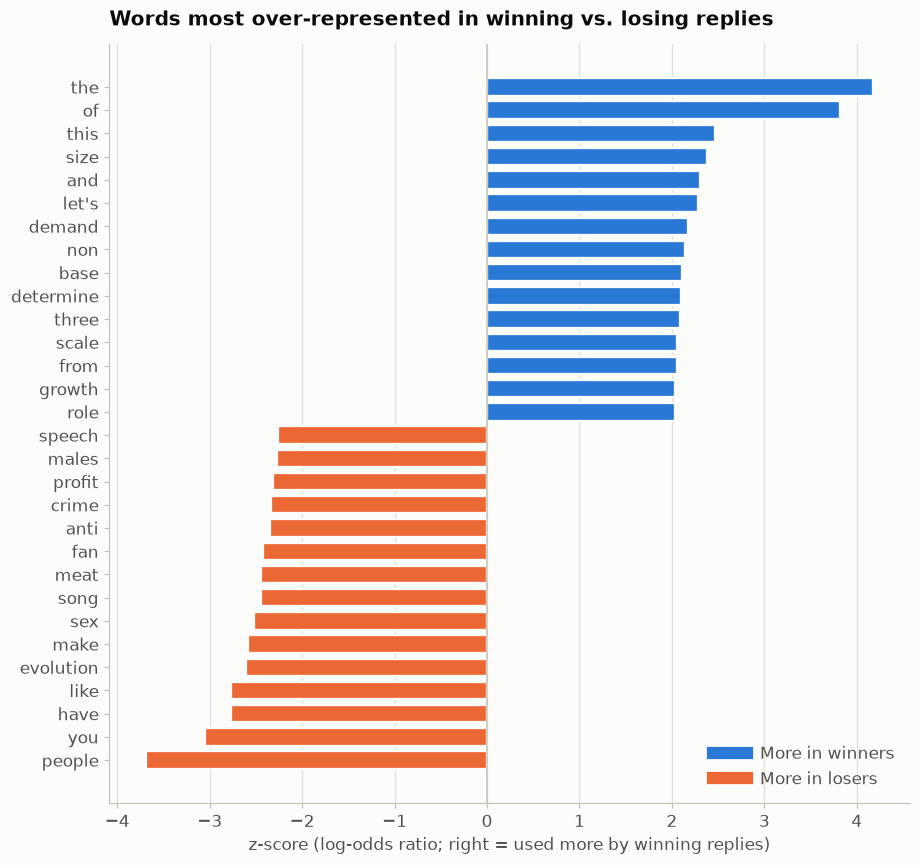

In [7]:
URL_RE = re.compile(r"\(?https?://\S+|www\.\S+")
texts = A.text_raw.map(lambda s: URL_RE.sub(" ", cd.clean_text(s, strip_delta=True)))
cv = CountVectorizer(token_pattern=r"(?u)\b[a-z][a-z']+\b", min_df=50)
X = cv.fit_transform(texts)
is_w = A.is_winner.to_numpy() == 1
yw, yl = np.asarray(X[is_w].sum(0)).ravel(), np.asarray(X[~is_w].sum(0)).ravel()
prior = yw + yl
nw, nl, a0 = yw.sum(), yl.sum(), prior.sum()
delta = np.log((yw + prior) / (nw + a0 - yw - prior)) - np.log((yl + prior) / (nl + a0 - yl - prior))
z = delta / np.sqrt(1 / (yw + prior) + 1 / (yl + prior))
words = pd.DataFrame({"word": cv.get_feature_names_out(), "z": z, "winner count": yw, "loser count": yl}).sort_values("z")

top = pd.concat([words.head(15), words.tail(15)])
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.barh(top.word, top.z, color=np.where(top.z > 0, WIN, LOSE), edgecolor=SURFACE, linewidth=1.5, height=0.75)
ax.axvline(0, color=AXIS, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("z-score (log-odds ratio; right = used more by winning replies)")
ax.set_title("Words most over-represented in winning vs. losing replies")
ax.legend(handles=[Line2D([], [], color=WIN, lw=8, label="More in winners"),
                   Line2D([], [], color=LOSE, lw=8, label="More in losers")], loc="lower right")
plt.tight_layout()
plt.show()

In [8]:
pd.concat({"more in winners": words.tail(25)[::-1].reset_index(drop=True),
           "more in losers": words.head(25).reset_index(drop=True)}, axis=1).round(2)

more in winners                                more in losers        \
              word     z winner count loser count           word     z   
0              the  4.18        50570       34195         people -3.69   
1               of  3.81        28808       19252            you -3.05   
2             this  2.46         7601        4991           have -2.77   
3             size  2.38          117          39           like -2.77   
4              and  2.31        26959       18434      evolution -2.61   
5            let's  2.28          391         196           make -2.58   
6           demand  2.18          141          55            sex -2.52   
7              non  2.14          519         279           song -2.45   
8             base  2.11          114          42           meat -2.45   
9        determine  2.10          129          50            fan -2.42   
10           three  2.09          229         106           anti -2.35   
11           scale  2.06          182          80          crime -2.34   
12            from  2.05         3912        2535         profit -2.32   
13          growth  2.04          108          40          males -2.27   
14            role  2.03          174          76         speech -2.26   
15             way  2.01         2384        1508     appreciate -2.23   
16      depression  2.00          227         107          don't -2.22   
17              on  2.00         7027        4672          money -2.21   
18            edit  1.98          280         139           hair -2.20   
19          search  1.95           84          29          would -2.18   
20             son  1.95           74          24          women -2.18   
21         initial  1.94           76          25       drinking -2.16   
22            goes  1.94          343         178             be -2.15   
23        contract  1.93          103          39      companies -2.15   
24           reach  1.93          103          39        because -2.12   

                             
   winner count loser count  
0          7176        5710  
1         18762       14124  
2          8754        6720  
3          3626        2904  
4            64          94  
5          2146        1762  
6           539         503  
7           107         132  
8           229         241  
9            61          87  
10          146         165  
11          232         240  
12          116         137  
13           24          45  
14          109         129  
15           54          76  
16         3837        2995  
17          996         847  
18           35          56  
19         5124        3944  
20          956         814  
21          123         139  
22        10048        7552  
23          201         207  
24         3959        3073

Some loser-side words are topics (evolution, meat, sex), not style. Because the two threads share an OP, these
are often the **OP's own topic words** repeated back. That matches the word-overlap result above.

## 4. When did winners join the discussion? (research question 2)

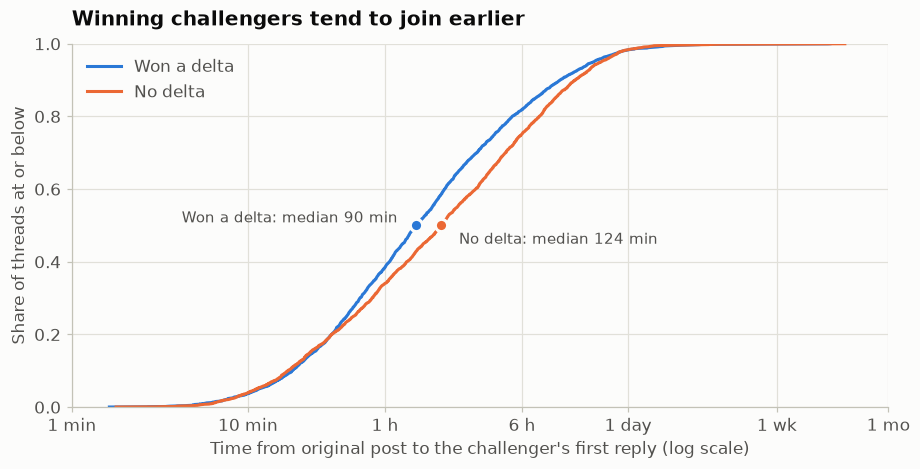

The earlier entrant won 54.4% of pairs (95% CI 52.6% to 56.2%)


In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for d, color, name, offset, ha in [(W.delay_hours, WIN, "Won a delta", (-12, 2), "right"),
                                   (L.delay_hours, LOSE, "No delta", (12, -12), "left")]:
    x = np.sort(d.dropna().clip(lower=1 / 60).to_numpy())
    yy = np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, yy, color=color, label=name)
    med = np.median(x)
    ax.plot([med], [0.5], "o", ms=8, color=color, mec=SURFACE, mew=2, zorder=3)
    ax.annotate(f"{name}: median {med * 60:.0f} min", (med, 0.5), xytext=offset, ha=ha, textcoords="offset points",
                color=INK2, fontsize=10)
ax.set_xscale("log")
ticks = [1 / 60, 10 / 60, 1, 6, 24, 24 * 7, 24 * 30]
ax.xaxis.set_major_locator(FixedLocator(ticks))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xticklabels(["1 min", "10 min", "1 h", "6 h", "1 day", "1 wk", "1 mo"])
ax.set_xlim(1 / 60, 24 * 30)
ax.set_ylim(0, 1)
ax.set_xlabel("Time from original post to the challenger's first reply (log scale)")
ax.set_ylabel("Share of threads at or below")
ax.set_title("Winning challengers tend to join earlier")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

earlier = (L.delay_hours - W.delay_hours).to_numpy()
s, lo, hi = win_share(earlier, groups)
print(f"The earlier entrant won {s:.1%} of pairs (95% CI {lo:.1%} to {hi:.1%})")

## What we see (train split; confirm on heldout before reporting)

1. **Repeating the OP's words is the strongest negative signal.** At equal length, a thread with 1 SD more word overlap with
   the OP has about 0.6× the odds of winning (OR 0.60, CI 0.53–0.68). It also loses in the length-matched subset (42% win share).
   The loser-side word list is full of the OP's own topic words. Winners bring new material rather than restating the OP.
   Tan et al. analyze this kind of reply–OP "interplay" in their paper; compare our result with theirs before writing it up.
2. **Concrete evidence helps; talking about evidence doesn't.** Including a link is the strongest positive text signal
   (OR 1.26, and a 66% win share in length-matched pairs). Numbers also favor winners (OR 1.13). Research words ("study",
   "evidence") and example phrases show no effect.
3. **Winners write in a more formal, informational register.** They use longer words (OR 1.20) and somewhat longer sentences,
   and more of "the", "of", "this". Losers lean on "people", "you", "like", "don't". Causal connectives ("because",
   "therefore") *favor losers* (OR 0.89). That's surprising, so read examples before interpreting it.
4. **Timing matters (Q2).** Winning challengers joined a median of 90 minutes after the OP, against 124 for losers. The earlier
   entrant won 54% of pairs, and joining earlier holds up after adjusting for length (OR 1.23).
5. **More back-and-forth helps only through length (Q2).** More comments looks good before adjustment (OR 1.21) but reverses
   at equal length (OR 0.85). Of two equally long threads, the one split across more replies tends to lose. One possible
   reason: a long exchange may mean the OP keeps pushing back.
6. **Lexicon proxies for ethos, pathos and stance show nothing clear.** Hedges, certainty, emotion (VADER), hostility,
   acknowledgment, personal experience, and I/you are all near 1. Either these matter less on CMV, or word lists are too
   crude to measure them. The hand-labeling pilot would tell us which.

**Implications for the tool:** evidence (links, numbers) and *novelty relative to the OP* are the best-supported signals.
Highlighting which of a draft's words merely echo the OP could be a compelling, explainable view. Claims about
ethos/pathos need better measures than word lists first.

## Caveats
- **Lexicon features are proxies.** "Research words" is not the same as citing evidence, and VADER was built for
  social-media sentiment, not rhetorical appeals. Before trusting a feature, print threads with high and low values:
  `A.sort_values("causal_rate").text`.
- **Associations, not causes.** Winners also differ in ways no feature captures (expertise, what the OP already half-believed).
- **Many comparisons on one split.** Treat these as hypotheses, then confirm the direction of each on the heldout split
  before writing it up.